# Dataloader Visualization

Sanity-check notebook for `DFC2020` (train, with labels) and `SEN12MS` (inference, S2-only).

Shows:
- Raw batches straight out of `build_data_loader` / `DataLoader`
- De-normalized RGB previews (S2 is stored normalized, so we invert `(x - mean) / std` for display)
- DFC2020 label masks overlaid next to the RGB image
- Per-batch tensor shapes, dtypes and value ranges (useful for catching the band-mismatch / normalization bugs this kind of pipeline tends to hit)


In [1]:
%load_ext autoreload
%autoreload 2

In [4]:
%matplotlib inline

import sys, os
from pathlib import Path

# --- EDIT THIS to point at the folder containing your `data/` package ---
PROJECT_ROOT = os.path.dirname(os.path.dirname(os.getcwd()))
sys.path.insert(0, str(PROJECT_ROOT))

import yaml
import numpy as np
import matplotlib.pyplot as plt
import torch

from data import DFC2020, SEN12MS
from data.load_data import load_data, build_data_loader

print("Project root:", PROJECT_ROOT)
print("Torch:", torch.__version__)


Project root: /data/workspace/denqos/Projects/S2_Segmentation
Torch: 2.6.0+cu124


## Load Config

In [5]:
config_path = os.path.join(PROJECT_ROOT, "configs")
with open(os.path.join(config_path, "dfc.yaml")) as f:
    dfc_cfg = yaml.safe_load(f)

with open(os.path.join(config_path, "sen12ms.yaml")) as f:
    sen12ms_cfg = yaml.safe_load(f)

print(yaml.dump(dfc_cfg["data"]))


batch_size: 256
dataset: dfc2020
drop_last: false
ignore_index: 255
image_size: 256
input_modalities:
- s2
- dfc
modality_mode: single
num_workers: 4
pin_memory: true
root_dir: ./Datasets/DFC_Public_Dataset/sensors
train:
  used_data_fraction: 1.0
val:
  used_data_fraction: 1.0
val_batch_size: 64



## Load Data: DFC2020

In [9]:
# Quick override so exploring the notebook stays fast; comment out to use the yaml value as-is
dfc_cfg["data"]["train"]["used_data_fraction"] = 0.01
dfc_cfg["data"]["root_dir"] = os.path.join(PROJECT_ROOT, "./Datasets/DFC_Public_Dataset/sensors")
train_dataset = DFC2020(dfc_cfg, split="train")
print(f"DFC2020 train samples loaded: {len(train_dataset)}")

sample_img, sample_label = train_dataset[0]
print("image tensor:", sample_img.shape, sample_img.dtype)
print("label tensor:", sample_label.shape, sample_label.dtype, "unique labels:", torch.unique(sample_label))


Using input modalities: ['s2', 'dfc']
S2 data normalized: min = -3.8392, max = 7.6778
DFC2020 train samples loaded: 5144
image tensor: torch.Size([3, 256, 256]) torch.float32
label tensor: torch.Size([256, 256]) torch.int64 unique labels: tensor([7])


In [13]:
from src.data.DFC2020 import S2_MEAN, S2_STD  # RGB-order mean/std used at prepare-time
S2_CLIP_THRESHOLD = 3000
def denorm_s2_to_rgb(x, normalized=True, gamma=1.0):
    """x: (3, H, W) array or tensor from the dataset -> (H, W, 3) float in [0, 1]."""
    x = np.asarray(x, dtype=np.float32)
    x = np.moveaxis(x, 0, -1)                 # CHW -> HWC
    if normalized:
        x = x * S2_STD + S2_MEAN              # undo standardization -> clipped reflectance
    x = np.clip(x / S2_CLIP_THRESHOLD, 0, 1)            # clip value is 3000, the usual display stretch
    return x ** gamma      



In [26]:
IGNORE_INDEX=255
def plot_processed_images(idx, dataset):
    fig, axes = plt.subplots(2, 8, figsize=(24, 6))
    for col, i in enumerate(idx):
        img = dataset[i][0]
        label = dataset[i][1]
        axes[0, col].imshow(denorm_s2_to_rgb(img))
        axes[0, col].set_title(f"#{i}", fontsize=10)
        lab = np.ma.masked_equal(label, IGNORE_INDEX)   # hide ignored pixels
        axes[1, col].imshow(lab, cmap="tab10", vmin=0, vmax=9, interpolation="nearest")
        for r in (0, 1):
            axes[r, col].axis("off")
    plt.tight_layout()
    plt.show()

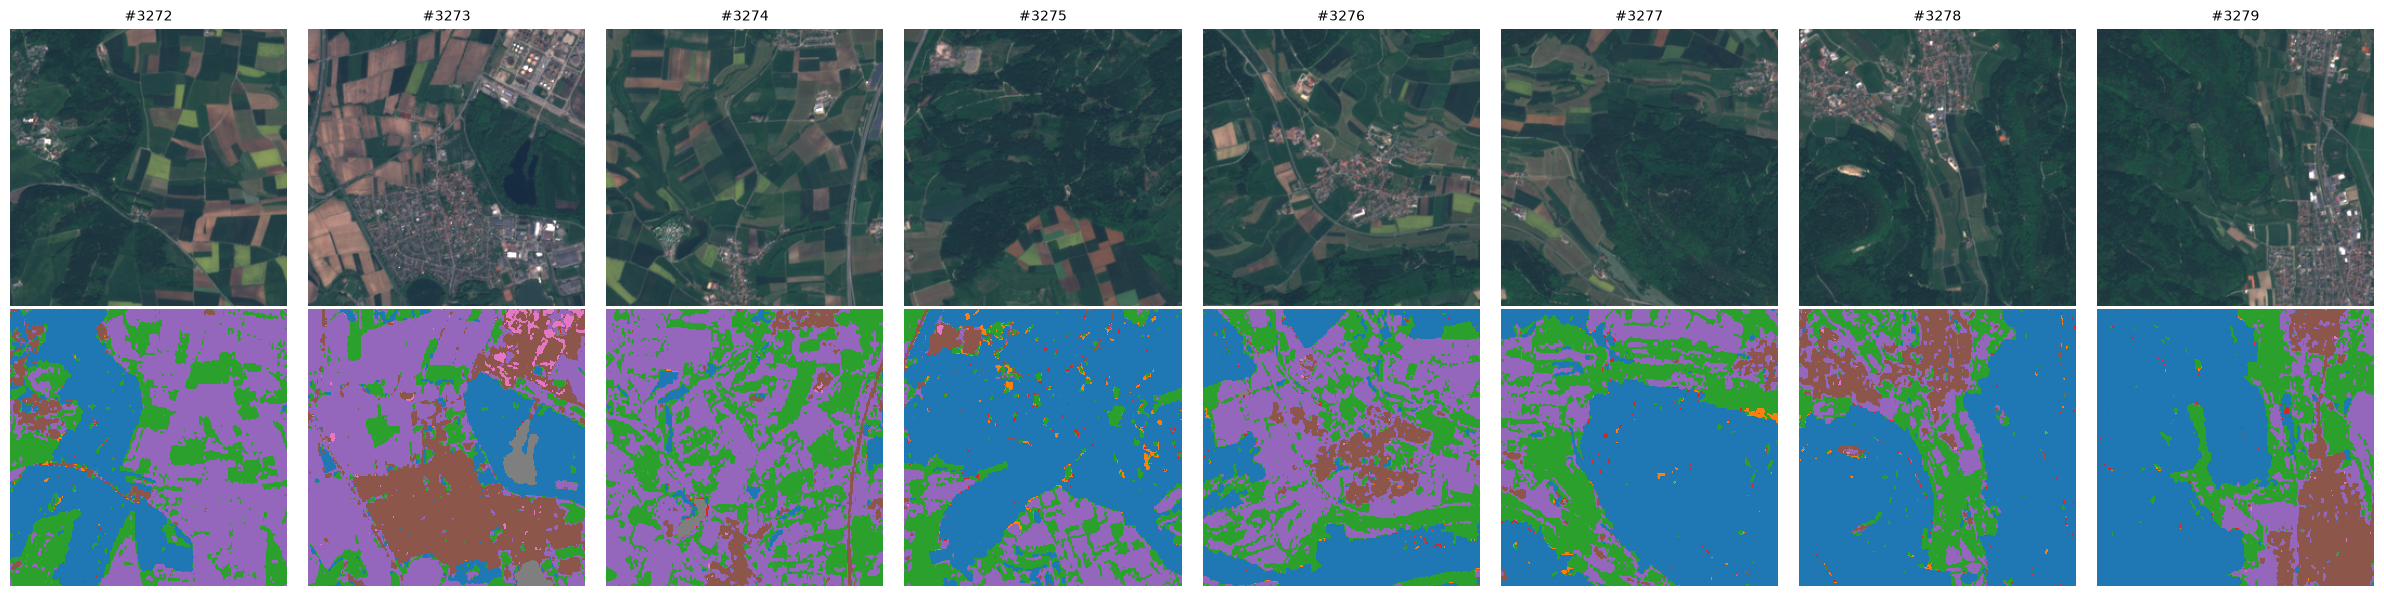

In [27]:
idx = np.arange(3272, 3280)
plot_processed_images(idx, train_dataset)

tensor(-1.0704) tensor(7.6778)
0.13266666 1.0


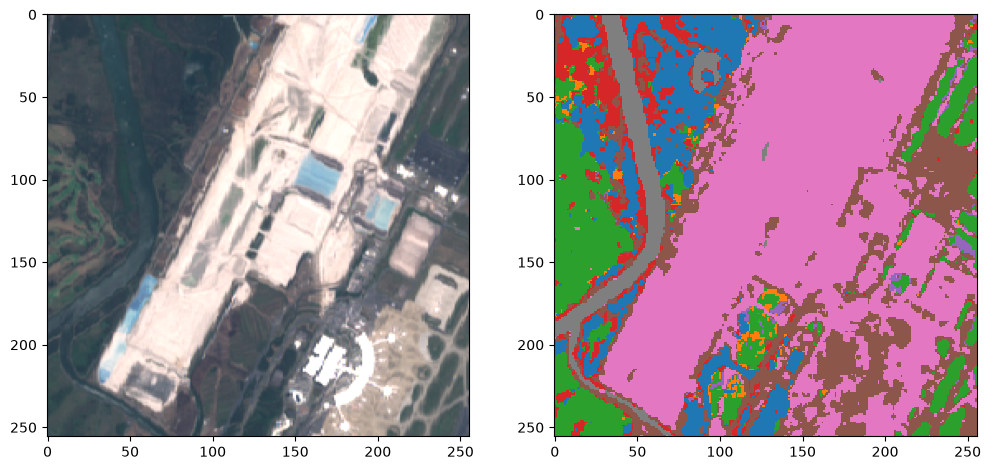

In [31]:
img_t, label_t = train_dataset[5059]
rgb = denorm_s2_to_rgb(img_t)
print(img_t.min(), img_t.max())
print(rgb.min(), rgb.max())
label = label_t.numpy().astype(float)

fig = plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(rgb)

plt.subplot(1, 2, 2)
plt.imshow(label, cmap="tab10", vmin=0, vmax=9, interpolation="nearest")
plt.show()